# Captum tour: model attribution

The two models are described in `01_data_and_models`.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

**Question**: which layers and units carry the signal, and is any of them full?

```python
LayerMethod(model, model.fc2).attribute(x, target=y)              # (N, 3) in narrow, (N, 64) in wide:
                                                                  # one number per example per fc2 unit
NeuronMethod(model, model.fc2).attribute(x, neuron_selector=u)    # (N, 16): which features drive fc2 unit u
```

Each plot shows both models. Layer and unit names follow §2.

## 12. `LayerActivation`: what the units output

```python
h2 = LayerActivation(model, model.fc2).attribute(x)     # = fc2 output: (N, 3) narrow, (N, 64) wide

plot 1:  relu(h2) for 100 examples (10 per class), narrow and wide side by side
         rows = examples, columns = fc2 units, colour = output (0 = off)

plot 2:  for layer in [fc1, fc2, fc3]:
             width_used = effective rank of the layer's output / its number of units   # 1 = all dimensions used
             dead       = share of units whose output is <= 0 for 99% of examples
```

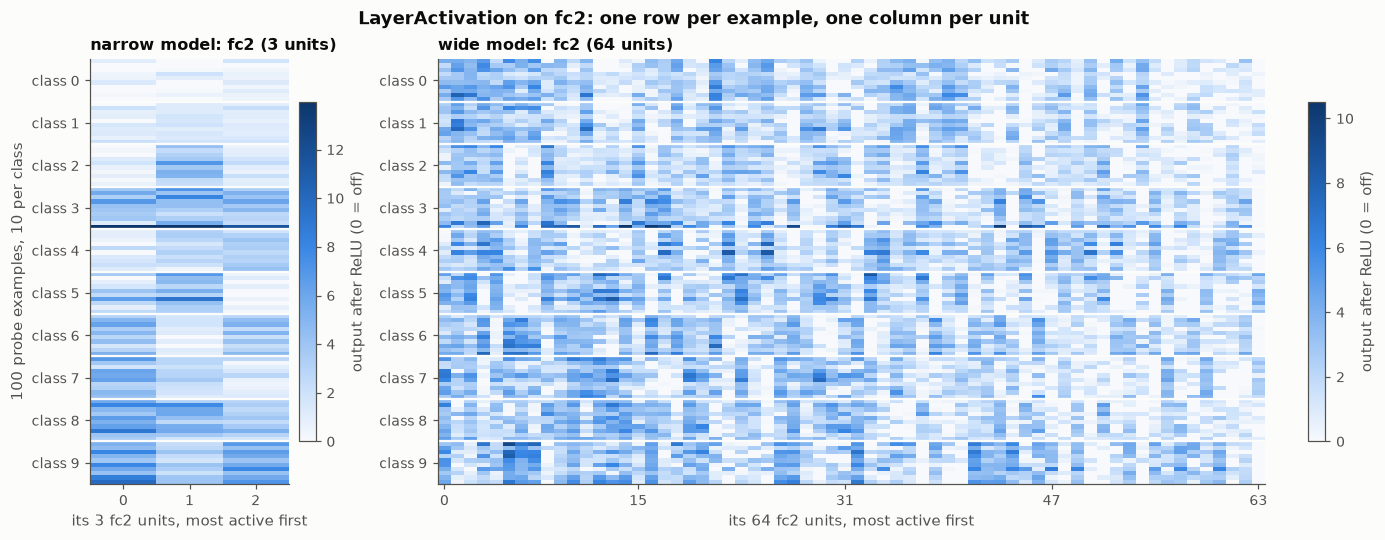

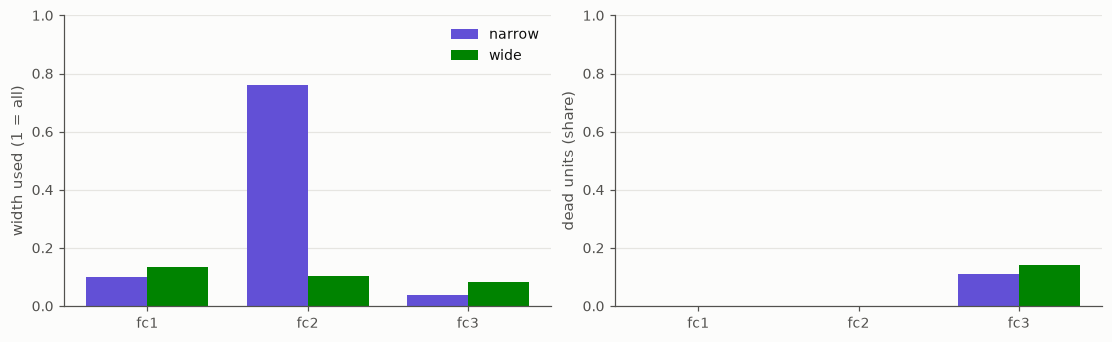

In [2]:

rows_by_class = torch.cat([(PY == c).nonzero().squeeze(1)[:10] for c in range(N_CLASSES)])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw=dict(width_ratios=[1.2, 5]))
for ax, name in zip(axes, ["narrow", "wide"]):
    a = layer_output(MODELS[name], "fc2")[rows_by_class].clamp_min(0)  # after the ReLU
    a = a[:, a.mean(0).argsort(descending=True)]
    im = ax.imshow(a.numpy(), aspect="auto", cmap=BLUES, interpolation="nearest")
    ax.set_yticks(np.arange(N_CLASSES) * 10 + 4.5, [f"class {c}" for c in range(N_CLASSES)])
    for c in range(1, N_CLASSES):
        ax.axhline(c * 10 - 0.5, color=SURFACE, lw=1.5)
    ax.grid(False)
    ax.set_xticks(range(a.shape[1]) if a.shape[1] <= 3 else [0, 15, 31, 47, 63])
    ax.set_xlabel(f"its {a.shape[1]} fc2 units, most active first")
    ax.set_title(f"{name} model: fc2 ({a.shape[1]} units)", loc="left")
    fig.colorbar(im, ax=ax, shrink=0.8, label="output after ReLU (0 = off)")
axes[0].set_ylabel("100 probe examples, 10 per class")
fig.suptitle("LayerActivation on fc2: one row per example, one column per unit", fontweight="bold", color=INK)
plt.show()

usage = pd.DataFrame([dict(model=name, layer=layer, width_used=width_used(m, layer), dead=dead_fraction(m, layer))
                      for name, m in MODELS.items() for layer in LAYERS])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, label in [(axes[0], "width_used", "width used (1 = all)"), (axes[1], "dead", "dead units (share)")]:
    for k, name in enumerate(["narrow", "wide"]):
        v = usage[usage.model == name][col].to_numpy()
        ax.bar(np.arange(3) + (k - 0.5) * 0.38, v, width=0.38, color=MODEL_COLOR[name], label=name)
    ax.set_xticks(range(3), LAYERS)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(label)
    ax.set_ylim(0, 1)
axes[0].legend(loc="upper right")
plt.show()

* Narrow `fc2` gives each class an on/off pattern over only 3 units, and its output uses most of those 3 dimensions.
  Some classes have to share a pattern: classes 0 and 1 are both near zero on all three units.
* Wide `fc2` uses about a tenth of its 64 dimensions. Only `fc3` has dead units (10–15%, in both models).

## 13. Layer attribution: how much each unit contributes to the score

```python
attr = LayerConductance(model, model.fc2).attribute(x, target=y)    # (N, units of fc2)
                                                                    # IntegratedGradients flowing through each unit
importance[u] = mean(|attr[:, u]|)                                  # one number per unit

plot: one row per method = importance / max(importance), units sorted by LayerConductance
      ρ = rank agreement with LayerConductance
```

The other methods, same output shape: `LayerGradientXActivation` (unit output × its gradient), `LayerIntegratedGradients`
(path in the layer's own output space), `InternalInfluence` (gradient along the path, no × output), and `LayerDeepLift`,
`LayerDeepLiftShap`, `LayerGradientShap`, `LayerLRP` (the §5 methods, stopped at this layer).

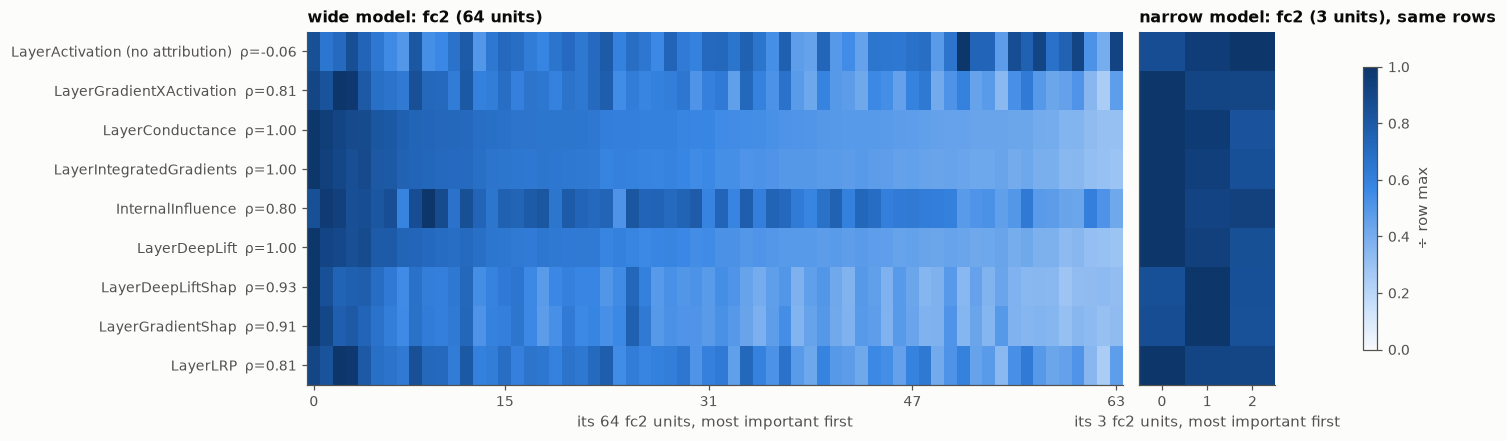

,narrow,wide
units carrying importance (share),,
fc1,0.840,0.952
fc2,0.997,0.965
fc3,0.844,0.835


In [3]:

LAYER_METHODS = {
    "LayerActivation (no attribution)": lambda m, l: LayerActivation(m, l).attribute(PX),
    "LayerGradientXActivation": lambda m, l: LayerGradientXActivation(m, l).attribute(PX, target=PY),
    "LayerConductance": lambda m, l: LayerConductance(m, l).attribute(PX, target=PY, n_steps=32),
    "LayerIntegratedGradients": lambda m, l: LayerIntegratedGradients(m, l).attribute(PX, target=PY, n_steps=32),
    "InternalInfluence": lambda m, l: InternalInfluence(m, l).attribute(PX, target=PY, n_steps=32),
    "LayerDeepLift": lambda m, l: LayerDeepLift(m, l).attribute(PX, target=PY),
    "LayerDeepLiftShap": lambda m, l: LayerDeepLiftShap(m, l).attribute(PX, baselines=DIST, target=PY),
    "LayerGradientShap": lambda m, l: LayerGradientShap(m, l).attribute(PX, baselines=DIST, target=PY, n_samples=20),
    "LayerLRP": lambda m, l: LayerLRP(m, l).attribute(PX, target=PY),
}
torch.manual_seed(0)
layer_scores = {name: {meth: f(MODELS[name], MODELS[name].fc2).detach().abs().mean(0) for meth, f in LAYER_METHODS.items()}
                for name in WIDTH}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw=dict(width_ratios=[6, 1]))
for ax, name in zip(axes, ["wide", "narrow"]):
    scores = layer_scores[name]
    order = scores["LayerConductance"].argsort(descending=True)
    grid = torch.stack([s[order] / s.max() for s in scores.values()]).numpy()
    im = ax.imshow(grid, aspect="auto", cmap=BLUES, vmin=0, vmax=1, interpolation="nearest")
    ax.grid(False)
    if name == "wide":
        ax.set_yticks(range(len(scores)), [f"{meth}  ρ={spearman(s, scores['LayerConductance']):.2f}"
                                           for meth, s in scores.items()])
    else:
        ax.set_yticks([])
    ax.set_xticks(range(WIDTH[name]) if WIDTH[name] <= 3 else [0, 15, 31, 47, 63])
    ax.set_xlabel(f"its {WIDTH[name]} fc2 units, most important first")
    ax.set_title(f"{name} model: fc2 ({WIDTH[name]} units)" + (", same rows" if name == "narrow" else ""), loc="left")
fig.colorbar(im, ax=axes, shrink=0.8, label="÷ row max")
plt.show()

util = pd.DataFrame({name: {layer: entropy_count(unit_importance(m, layer)) / m.get_submodule(layer).out_features
                            for layer in LAYERS} for name, m in MODELS.items()})
display(util.rename_axis("units carrying importance (share)"))

* The path methods (Conductance, LayerIntegratedGradients, LayerDeepLift and the Shap variants) rank the wide units almost
  identically. Raw activation size barely predicts importance.
* In the narrow model every method gives each of the 3 units about the same weight: all are fully used.

## 14. Layer perturbation: what breaks when a unit is switched off

```python
for layer in [fc1, fc2, fc3]:
    for each unit u:
        ablation[u]    = mean |score(x) - score(x with unit u's output set to 0)|    # LayerFeatureAblation
        permutation[u] = mean |score(x) - score(x with unit u's output shuffled)|    # LayerFeaturePermutation

plot: costs sorted from highest to lowest, one line per layer
```

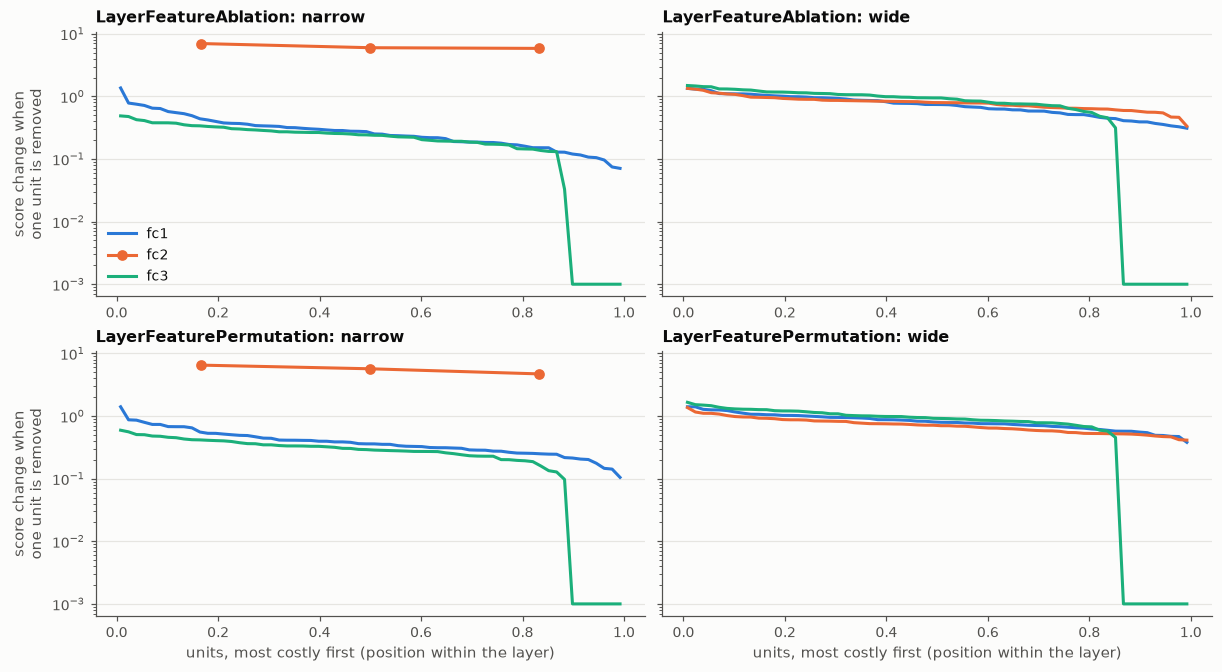

In [4]:
unit_cost = {}  # unit_cost(model, layer, method) is in toy.py: LayerFeatureAblation / LayerFeaturePermutation
for name, model in MODELS.items():
    for layer in LAYERS:
        for method in ["LayerFeatureAblation", "LayerFeaturePermutation"]:
            unit_cost[(method, name, layer)] = unit_cost_of(model, layer, method)

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for i, method in enumerate(["LayerFeatureAblation", "LayerFeaturePermutation"]):
    for j, name in enumerate(["narrow", "wide"]):
        ax = axes[i, j]
        for layer in LAYERS:
            v = unit_cost[(method, name, layer)].sort(descending=True).values.clamp_min(1e-3).numpy()
            x = (np.arange(len(v)) + 0.5) / len(v)
            ax.plot(x, v, color=LAYER_COLOR[layer], marker="o" if len(v) <= 3 else None, label=layer)
        ax.set_yscale("log")
        ax.set_title(f"{method}: {name}", loc="left")
        if i == 1:
            ax.set_xlabel("units, most costly first (position within the layer)")
        if j == 0:
            ax.set_ylabel("score change when\none unit is removed")
axes[0, 0].legend(loc="lower left")
plt.show()

* Removing one narrow `fc2` unit moves the score about 20× as much as removing an `fc1` or `fc3` unit:
  the layer has no spare units.
* In the wide model, `fc2` units are as cheap to lose as any other. Ablation and permutation agree.

## 15. Neuron attribution: which input features drive one unit

```python
attr = NeuronIntegratedGradients(model, model.fc2).attribute(x, neuron_selector=u)    # (N, 16)
plot 1: for the busiest fc2 unit, one row per method = share of mean |attr| per feature

# NeuronConductance: only the part of the class score that flows through unit u, so it needs target
attr = NeuronConductance(model, model.fc2).attribute(x, neuron_selector=u, target=y)
plot 2: one row per fc2 unit;   load[u] = sum over features of mean |attr|
```

Plot 1 methods: `NeuronGradient`, `NeuronIntegratedGradients`, `NeuronDeepLift`, `NeuronDeepLiftShap`, `NeuronGradientShap`,
`NeuronGuidedBackprop`, `NeuronDeconvolution`, `NeuronFeatureAblation` (the Part 3 ideas, applied to one unit's output) and
`NeuronConductance`. This joins the two frames: a unit of the model, broken down by input feature.

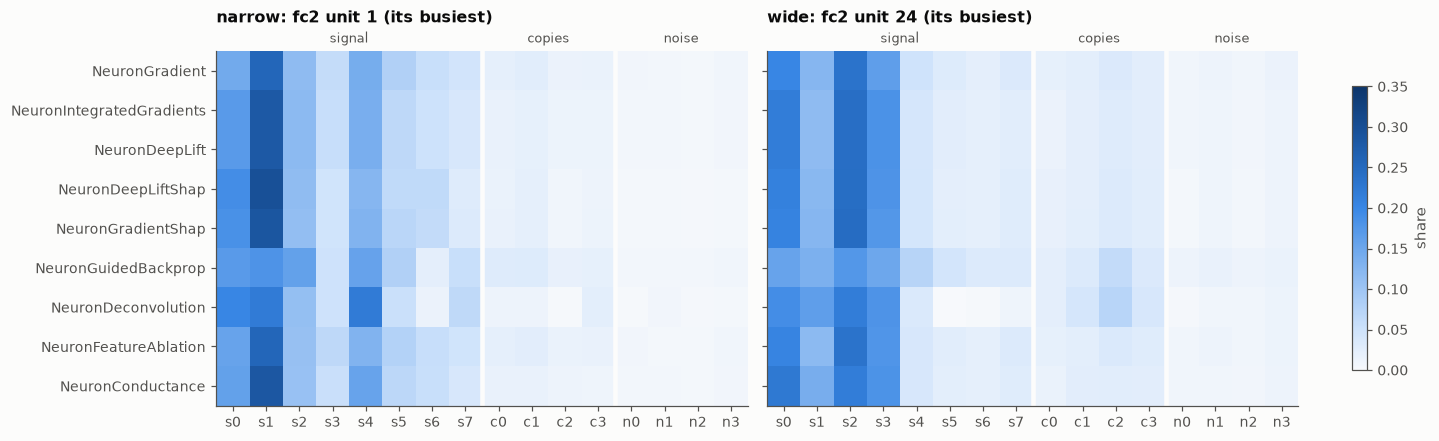

In [5]:
NEURON_METHODS = {
    "NeuronGradient": lambda m, l, j: NeuronGradient(m, l).attribute(PX, neuron_selector=j),
    "NeuronIntegratedGradients": lambda m, l, j: NeuronIntegratedGradients(m, l).attribute(PX, neuron_selector=j, n_steps=32),
    "NeuronDeepLift": lambda m, l, j: NeuronDeepLift(m, l).attribute(PX, neuron_selector=j),
    "NeuronDeepLiftShap": lambda m, l, j: NeuronDeepLiftShap(m, l).attribute(PX, neuron_selector=j, baselines=DIST),
    "NeuronGradientShap": lambda m, l, j: NeuronGradientShap(m, l).attribute(PX, neuron_selector=j, baselines=DIST, n_samples=20),
    "NeuronGuidedBackprop": lambda m, l, j: NeuronGuidedBackprop(m, l).attribute(PX, neuron_selector=j),
    "NeuronDeconvolution": lambda m, l, j: NeuronDeconvolution(m, l).attribute(PX, neuron_selector=j),
    "NeuronFeatureAblation": lambda m, l, j: NeuronFeatureAblation(m, l).attribute(PX, neuron_selector=j),
    "NeuronConductance": lambda m, l, j: NeuronConductance(m, l).attribute(PX, neuron_selector=j, target=PY, n_steps=32),
}
busiest = {name: int(layer_scores[name]["LayerConductance"].argmax()) for name in WIDTH}
torch.manual_seed(0)
neuron_maps = {name: torch.stack([share(f(MODELS[name], MODELS[name].fc2, busiest[name]).detach())
                                  for f in NEURON_METHODS.values()]) for name in WIDTH}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    im = feature_heatmap(ax, neuron_maps[name].numpy(), list(NEURON_METHODS), vmin=0, vmax=0.35)
    ax.set_title(f"{name}: fc2 unit {busiest[name]} (its busiest)", loc="left")
fig.colorbar(im, ax=axes, shrink=0.8, label="share")
plt.show()

* All nine agree on what drives the unit, except GuidedBackprop and Deconvolution (as in §4).
* NeuronConductance differs slightly from the rest: it counts only the part of the unit's output that reaches the
  class score.

**Every `fc2` unit × feature**, with `NeuronConductance` (narrow: all 3 units; wide: its 12 busiest; same colour scale).
Each unit's **load** = the total class score that flows through it.

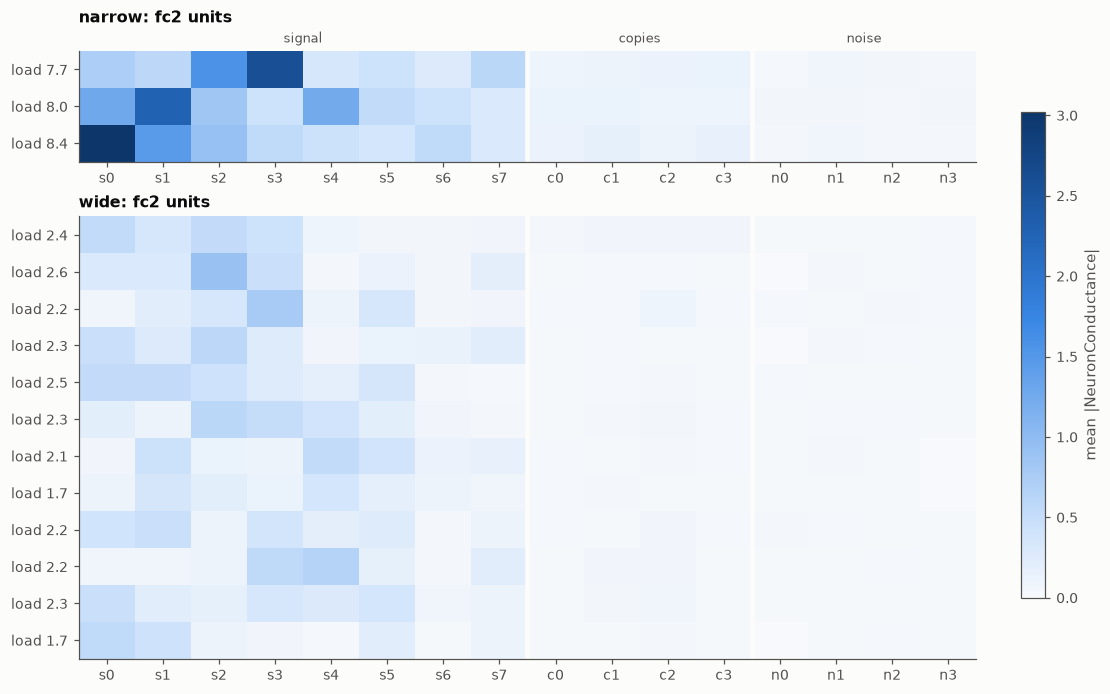

{'narrow': 'mean load per unit 8.0', 'wide': 'mean load per unit 2.2'}


In [6]:
def unit_feature_map(model, units):
    nc = NeuronConductance(model, model.fc2)
    return torch.stack([nc.attribute(PX, neuron_selector=int(j), target=PY, n_steps=16).detach().abs().mean(0)
                        for j in units])


maps = {"narrow": unit_feature_map(NARROW, range(3)),
        "wide": unit_feature_map(WIDE, layer_scores["wide"]["LayerConductance"].argsort(descending=True)[:12])}
vmax = max(m.max().item() for m in maps.values())
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), gridspec_kw=dict(height_ratios=[3, 12]))
for ax, name in zip(axes, ["narrow", "wide"]):
    im = feature_heatmap(ax, maps[name].numpy(), [f"load {v:.1f}" for v in maps[name].sum(1)], vmin=0, vmax=vmax,
                         group_labels=(name == "narrow"))
    ax.set_title(f"{name}: fc2 units", loc="left")
fig.colorbar(im, ax=axes, shrink=0.8, label="mean |NeuronConductance|")
plt.show()
print({name: f"mean load per unit {maps[name].sum(1).mean():.1f}" for name in WIDTH})

* Each narrow `fc2` unit carries about 3.5× the load of even the busiest wide units, and every one of them mixes
  most of the eight signals.
* In the wide model the work is spread over many units, each carrying a lighter mix.

## 16. Model view of convergence: are the units' roles still changing?

```python
for epoch in 0, 2, 4, ..., 60:
    imp[epoch]   = LayerConductance importance per unit (§13), with that epoch's weights
    drift[epoch] = 1 - cosine(imp[epoch], imp[epoch - 2])        # 0 = unit roles unchanged
```

conductance at 31 checkpoints x 2 models in 4s


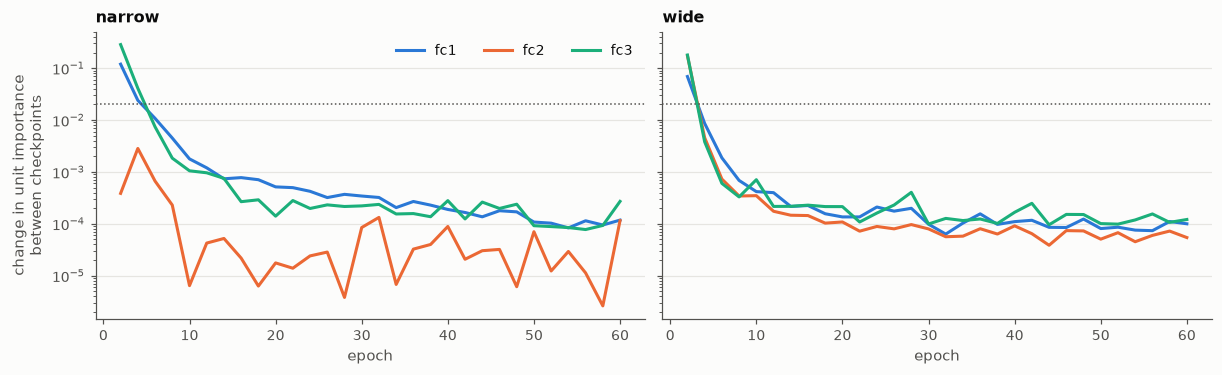

In [7]:

def conductance_drift(name):
    rows, prev = [], {}
    for e in EPOCH_GRID:
        model = load(WIDTH[name], CKPTS[name][e])
        for layer in LAYERS:
            imp = unit_importance(model, layer, n_steps=16)
            if layer in prev:
                rows.append(dict(epoch=e, layer=layer, drift=1 - F.cosine_similarity(imp, prev[layer], dim=0).item()))
            prev[layer] = imp
    return pd.DataFrame(rows)


t0 = time.time()
drift = {name: conductance_drift(name) for name in WIDTH}
print(f"conductance at {len(EPOCH_GRID)} checkpoints x 2 models in {time.time() - t0:.0f}s")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, name in zip(axes, ["narrow", "wide"]):
    for layer in LAYERS:
        d = drift[name][drift[name].layer == layer]
        ax.plot(d.epoch, d.drift.clip(lower=1e-7), color=LAYER_COLOR[layer], label=layer)
    ax.axhline(0.02, color=INK2, lw=1, ls=":")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_title(name, loc="left")
axes[0].set_ylabel("change in unit importance\nbetween checkpoints")
axes[0].legend(loc="upper right", ncol=3)
plt.show()

Unit roles settle within a few epochs in every layer of both models. Drift catches a run stopped very early, but it
cannot tell a converged layer from a stuck one. Part 5 can.